# Ruta 14 · Residuos sólidos — Extracción y perfilamiento inicial

**Proyecto integrador · Visualización de datos · Entrega 1 (semana 1)**

Este notebook cubre lo que pide la primera entrega: registrar la fuente, conservar el dato bruto sin modificar,
perfilar su calidad y comprobar que la unión con la capa geográfica es viable. El ETL completo y la matriz de
visualizaciones corresponden a la semana 2.

Fuentes (NYC Open Data, descargadas el 30/10/2026):

| Archivo | Conjunto | ID | Publica |
|---|---|---|---|
| `dsny_monthly_tonnage_raw.csv` | DSNY Monthly Tonnage Data | `ebb7-mvp5` | Department of Sanitation (DSNY) |
| `nyc_community_districts.geojson` | Community Districts | `5crt-au7u` | Department of City Planning (DCP) |
| `nyc_population_by_cd.csv` | New York City Population By Community Districts | `xi7c-iiu2` | Department of City Planning (DCP) |

Funciona en local (con el `.venv` del proyecto) y en Google Colab: si no encuentra los archivos brutos, los descarga de la URL oficial.

In [1]:
# En Colab, descomentar la siguiente línea:
# !pip install -q pandas numpy matplotlib geopandas pyarrow openpyxl
import hashlib, json, platform
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import geopandas as gpd

print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| geopandas", gpd.__version__, "| matplotlib", matplotlib.__version__)

Python 3.15.2 | pandas 3.1.0 | geopandas 1.2.0 | matplotlib 3.11.2


In [2]:
# Rutas relativas a la raíz del proyecto (el notebook vive en 02_etl/)
ROOT = Path.cwd().parent if Path.cwd().name == "02_etl" else Path.cwd()
RAW = ROOT / "01_datos" / "bruto"
PROC = ROOT / "01_datos" / "procesado"
FIG = ROOT / "03_visualizaciones" / "entrega1"
TAB = ROOT / "02_etl" / "salidas"
for p in (RAW, PROC, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

FUENTES = {
    "dsny_monthly_tonnage_raw.csv":
        "https://data.cityofnewyork.us/api/views/ebb7-mvp5/rows.csv?accessType=DOWNLOAD",
    "nyc_community_districts.geojson":
        "https://data.cityofnewyork.us/resource/5crt-au7u.geojson?$limit=100",
    "nyc_population_by_cd.csv":
        "https://data.cityofnewyork.us/api/views/xi7c-iiu2/rows.csv?accessType=DOWNLOAD",
    "DSNY_Monthly_Tonnage_Data_Dictionary.xlsx":
        "https://data.cityofnewyork.us/api/views/ebb7-mvp5/files/b9c2fb92-d30a-43a9-b259-3b9f9d69a1f6"
        "?download=true&filename=DSNY_Monthly_Tonnage_Data_Data_Dictionary-2026-04-16.xlsx",
}

# Paleta apta para daltonismo (Okabe-Ito)
OI = {"rechazo": "#555555", "papel": "#0072B2", "mgp": "#E69F00", "organicos": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Extracción

El archivo bruto **no se modifica**. Se registra tamaño, huella SHA-256 y conteo de filas para poder verificar
más adelante que el procesamiento parte exactamente del mismo archivo.

In [3]:
import urllib.request

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

registro = []
for nombre, url in FUENTES.items():
    destino = RAW / nombre
    if not destino.exists():
        print("Descargando", nombre)
        urllib.request.urlretrieve(url, destino)
    registro.append({"archivo": nombre, "url": url, "bytes": destino.stat().st_size,
                     "sha256": sha256(destino)})

registro_extraccion = pd.DataFrame(registro)
registro_extraccion.to_csv(TAB / "registro_extraccion.csv", index=False)
registro_extraccion

,archivo,url,bytes,sha256
0,dsny_monthly_tonnage_raw.csv,https://data.cityofnewyork.us/api/views/ebb7-m...,1215880,1a7e64e6f77125e228fdc620af1d0336bbf2ae0d94e3a7...
1,nyc_community_districts.geojson,https://data.cityofnewyork.us/resource/5crt-au...,3793109,4bd95ec20da3dcaba4a92b396c4da49508dc92ef680f1d...
2,nyc_population_by_cd.csv,https://data.cityofnewyork.us/api/views/xi7c-i...,4378,5d08ca3dec654938b1909bbc99a9876fad94d948b12648...
3,DSNY_Monthly_Tonnage_Data_Dictionary.xlsx,https://data.cityofnewyork.us/api/views/ebb7-m...,117380,19e7f850e77bb8353706cad297da213a48c0fe9e87aac2...


In [4]:
raw = pd.read_csv(RAW / "dsny_monthly_tonnage_raw.csv", dtype={"COMMUNITYDISTRICT": str, "BOROUGH_ID": str})
print("Filas:", len(raw), "| Columnas:", raw.shape[1])
raw.head()

Filas: 25296 | Columnas: 12


,MONTH,BOROUGH,COMMUNITYDISTRICT,REFUSETONSCOLLECTED,PAPERTONSCOLLECTED,MGPTONSCOLLECTED,RESORGANICSTONS,SCHOOLORGANICTONS,LEAVESORGANICTONS,XMASTREETONS,OTHERORGANICSTONS,BOROUGH_ID
0,2026 / 09,Bronx,01,3517.0,261.4,140.8,25.8,58.7,NaN,NaN,NaN,2
1,2026 / 09,Bronx,02,8050.7,279.3,214.3,15.8,53.5,NaN,NaN,NaN,2
2,2026 / 09,Bronx,03,2323.6,196.4,167.5,22.3,72.6,NaN,NaN,NaN,2
3,2026 / 09,Bronx,04,4372.1,259.8,290.1,25.1,NaN,NaN,NaN,0.7,2
4,2026 / 09,Bronx,05,3704.5,268.7,319.6,18.8,51.0,NaN,NaN,NaN,2


## 2. Perfilamiento del dato bruto

Estructura, tipos, faltantes, duplicados y rangos. Ninguna celda de esta sección altera `raw`.

In [5]:
TON_COLS = ["REFUSETONSCOLLECTED", "PAPERTONSCOLLECTED", "MGPTONSCOLLECTED", "RESORGANICSTONS",
            "SCHOOLORGANICTONS", "LEAVESORGANICTONS", "XMASTREETONS", "OTHERORGANICSTONS"]

perfil = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "no_nulos": raw.notna().sum(),
    "nulos": raw.isna().sum(),
    "pct_nulos": (raw.isna().mean() * 100).round(1),
    "valores_unicos": raw.nunique(),
})
num = raw[TON_COLS].describe().T[["min", "50%", "mean", "max"]].round(1)
perfil = perfil.join(num)
perfil.to_csv(TAB / "perfil_columnas.csv")
perfil

,tipo,no_nulos,nulos,pct_nulos,valores_unicos,min,50%,mean,max
MONTH,str,25296,0,0.0,437,NaN,NaN,NaN,NaN
BOROUGH,str,25296,0,0.0,5,NaN,NaN,NaN,NaN
COMMUNITYDISTRICT,str,25296,0,0.0,18,NaN,NaN,NaN,NaN
REFUSETONSCOLLECTED,float64,25296,0,0.0,20175,8.4,4061.6,4239.9,10413.9
PAPERTONSCOLLECTED,float64,22862,2434,9.6,8740,0.0,398.6,447.7,2129.7
MGPTONSCOLLECTED,float64,23219,2077,8.2,7106,0.0,334.9,354.8,1254.6
RESORGANICSTONS,float64,3744,21552,85.2,1824,0.4,65.8,95.3,785.5
SCHOOLORGANICTONS,float64,2689,22607,89.4,1078,0.1,43.8,54.5,265.7
LEAVESORGANICTONS,float64,881,24415,96.5,693,0.6,58.6,166.2,1857.3
XMASTREETONS,float64,1685,23611,93.3,568,0.4,18.0,26.3,186.0


In [6]:
clave = ["MONTH", "BOROUGH", "COMMUNITYDISTRICT"]
meses = pd.to_datetime(raw["MONTH"].str.replace(" / ", "-") + "-01", format="%Y-%m-%d")
por_mes = raw.groupby("MONTH").size()
rango_completo = pd.date_range(meses.min(), meses.max(), freq="MS")

checks = {
    "filas": len(raw),
    "filas_duplicadas_exactas": int(raw.duplicated().sum()),
    "claves_duplicadas_(mes,distrito)": int(raw.duplicated(subset=clave).sum()),
    "primer_mes": meses.min().strftime("%Y-%m"),
    "ultimo_mes": meses.max().strftime("%Y-%m"),
    "meses_esperados": len(rango_completo),
    "meses_presentes": meses.nunique(),
    "meses_ausentes": ", ".join(d.strftime("%Y-%m") for d in sorted(set(rango_completo) - set(meses))),
    "distritos_unicos": raw.groupby(["BOROUGH_ID", "COMMUNITYDISTRICT"]).ngroups,
    "meses_con_59_distritos": int((por_mes == 59).sum()),
    "meses_con_menos_de_59": int((por_mes < 59).sum()),
    "valores_negativos": int((raw[TON_COLS] < 0).sum().sum()),
    "rechazo_igual_a_cero": int((raw["REFUSETONSCOLLECTED"] == 0).sum()),
    "borough_vs_id_inconsistentes": int(raw.groupby("BOROUGH")["BOROUGH_ID"].nunique().gt(1).sum()),
}
checks_df = pd.Series(checks, name="valor").to_frame()
checks_df.to_csv(TAB / "controles_calidad.csv")
checks_df

,valor
filas,25296
filas_duplicadas_exactas,0
"claves_duplicadas_(mes,distrito)",0
primer_mes,1990-01
ultimo_mes,2026-09
meses_esperados,441
meses_presentes,437
meses_ausentes,"1990-02, 1990-03, 1990-04, 1990-05"
distritos_unicos,59
meses_con_59_distritos,423


In [7]:
# Meses incompletos (si existen) y distritos que faltan en ellos
incompletos = por_mes[por_mes < 59]
print(incompletos.sort_index().tail(15))
print("Combinaciones BOROUGH / BOROUGH_ID:")
print(raw.groupby(["BOROUGH", "BOROUGH_ID"]).size())

MONTH
1990 / 01     3
1990 / 06     3
1990 / 07     3
1990 / 08     9
1990 / 09     9
1990 / 10    18
1990 / 11    22
1990 / 12    22
1991 / 01    31
1991 / 02    32
1991 / 03    32
1991 / 04    45
1991 / 05    52
1991 / 12    58
dtype: int64
Combinaciones BOROUGH / BOROUGH_ID:
BOROUGH        BOROUGH_ID
Bronx          2             5127
Brooklyn       3             7659
Manhattan      1             5197
Queens         4             6004
Staten Island  5             1309
dtype: int64


### 2.1 ¿Los nulos son faltantes o “servicio inexistente”?

Las columnas de orgánicos tienen muchos nulos. Antes de decidir cómo tratarlos se revisa **desde cuándo**
aparece cada flujo con datos. Si los nulos se concentran antes del inicio de un servicio, no son errores sino
ausencia de servicio (nulo estructural) y no deben imputarse como si fueran pérdidas de registro.

In [8]:
raw_f = raw.assign(fecha=meses)
inicio = {}
for c in TON_COLS:
    con_dato = raw_f.loc[raw_f[c].notna(), "fecha"]
    inicio[c] = {
        "primer_mes_con_dato": con_dato.min().strftime("%Y-%m") if len(con_dato) else None,
        "pct_nulos_total": round(raw_f[c].isna().mean() * 100, 1),
        "pct_nulos_desde_2024-10": round(raw_f.loc[raw_f.fecha >= "2024-10-01", c].isna().mean() * 100, 1),
    }
inicio_df = pd.DataFrame(inicio).T
inicio_df.to_csv(TAB / "inicio_flujos.csv")
inicio_df

,primer_mes_con_dato,pct_nulos_total,pct_nulos_desde_2024-10
REFUSETONSCOLLECTED,1990-01,0.0,0.0
PAPERTONSCOLLECTED,1993-01,9.6,0.0
MGPTONSCOLLECTED,1993-04,8.2,0.0
RESORGANICSTONS,2013-05,85.2,0.0
SCHOOLORGANICTONS,2012-09,89.4,41.5
LEAVESORGANICTONS,1993-11,96.5,100.0
XMASTREETONS,1994-01,93.3,100.0
OTHERORGANICSTONS,1993-04,94.8,81.0


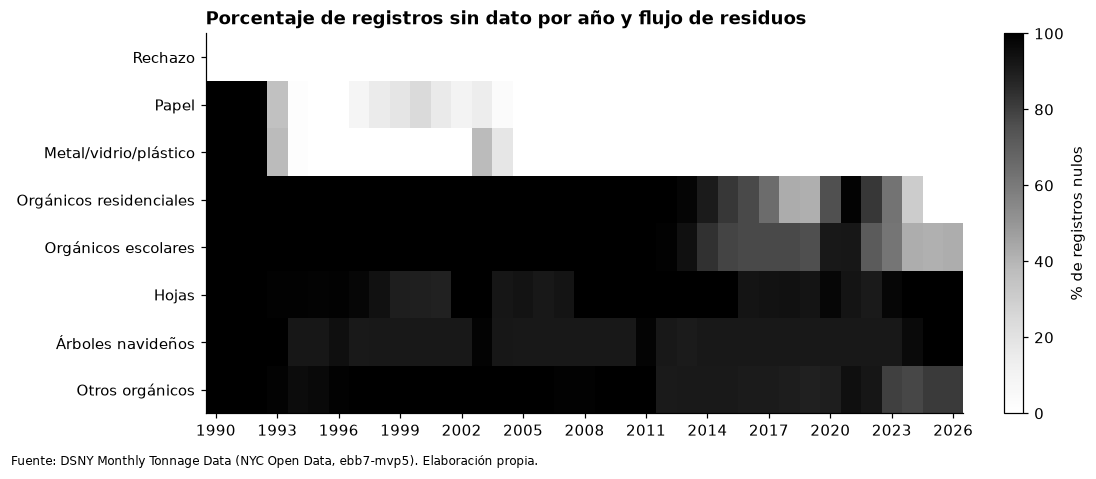

In [9]:
# Figura 1 · Porcentaje de distritos sin dato por año y flujo
nulos_anio = raw_f.groupby(raw_f.fecha.dt.year)[TON_COLS].apply(lambda d: d.isna().mean() * 100)
etiquetas = ["Rechazo", "Papel", "Metal/vidrio/plástico", "Orgánicos residenciales", "Orgánicos escolares",
             "Hojas", "Árboles navideños", "Otros orgánicos"]
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(nulos_anio.T.values, aspect="auto", cmap="Greys", vmin=0, vmax=100)
ax.set_yticks(range(len(TON_COLS)), etiquetas)
anios = nulos_anio.index.tolist()
paso = 3
ax.set_xticks(range(0, len(anios), paso), anios[::paso])
ax.set_title("Porcentaje de registros sin dato por año y flujo de residuos", loc="left", fontweight="bold")
cb = fig.colorbar(im, ax=ax, fraction=0.025)
cb.set_label("% de registros nulos")
fig.text(0.01, -0.02, "Fuente: DSNY Monthly Tonnage Data (NYC Open Data, ebb7-mvp5). Elaboración propia.", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig1_nulos_por_anio.png", bbox_inches="tight")
plt.show()

## 3. Preparación preliminar (versión 0)

Reglas aplicadas, todas reversibles y documentadas en la bitácora:

1. `MONTH` (“2026 / 09”) → `fecha` (primer día del mes).
2. `boro_cd` = `BOROUGH_ID` × 100 + `COMMUNITYDISTRICT` (formato de la capa del DCP, p. ej. Bronx 01 → 201).
3. Agrupación de flujos: **rechazo** (`REFUSE`), **papel**, **MGP** y **orgánicos** (residenciales, hojas, árboles navideños y otros).
   Los **orgánicos escolares quedan fuera** de los totales por distrito: según el diccionario de DSNY, esos camiones
   cruzan límites de distrito y su tonelaje no puede asignarse a un distrito.
4. Nulo en un flujo se trata como **0 t solo para calcular totales y proporciones**; las columnas originales se mantienen sin imputar.
5. Se excluye el mes más reciente si está incompleto (menos de 59 distritos).
6. Para pasar a kg se usa la tonelada corta (1 ton = 907,185 kg). El diccionario no declara la unidad; es un supuesto
   que se registra en la ficha de calidad.

In [10]:
df = raw.copy()
df["fecha"] = meses
df["boro_cd"] = df["BOROUGH_ID"].astype(int) * 100 + df["COMMUNITYDISTRICT"].astype(int)
org_cols = ["RESORGANICSTONS", "LEAVESORGANICTONS", "XMASTREETONS", "OTHERORGANICSTONS"]  # sin escolares
KG_POR_TON = 907.185  # supuesto: tonelada corta (EE. UU.)
df["t_rechazo"] = df["REFUSETONSCOLLECTED"].fillna(0)
df["t_papel"] = df["PAPERTONSCOLLECTED"].fillna(0)
df["t_mgp"] = df["MGPTONSCOLLECTED"].fillna(0)
df["t_organicos"] = df[org_cols].fillna(0).sum(axis=1)
df["t_total"] = df[["t_rechazo", "t_papel", "t_mgp", "t_organicos"]].sum(axis=1)
df["t_desviado"] = df["t_total"] - df["t_rechazo"]
df["tasa_desvio"] = np.where(df["t_total"] > 0, df["t_desviado"] / df["t_total"], np.nan)

ultimo = df["fecha"].max()
if (df["fecha"] == ultimo).sum() < 59:
    df = df[df["fecha"] < ultimo]

print("Filas antes:", len(raw), "| después:", len(df))
print("Suma de control rechazo (bruto vs procesado):",
      round(raw["REFUSETONSCOLLECTED"].sum(), 1), "vs", round(df["t_rechazo"].sum(), 1))

Filas antes: 25296 | después: 25296
Suma de control rechazo (bruto vs procesado): 107252492.0 vs 107252492.0


In [11]:
# Población: el conjunto de DCP llega hasta el censo 2010. Se usa como denominador aproximado
# y esto se declara como limitación (ver ficha de calidad).
pop = pd.read_csv(RAW / "nyc_population_by_cd.csv")
boro_id = {"Manhattan": 1, "Bronx": 2, "Brooklyn": 3, "Queens": 4, "Staten Island": 5}
pop["boro_cd"] = pop["Borough"].map(boro_id) * 100 + pop["CD Number"]
pop = pop.rename(columns={"CD Name": "nombre_distrito", "2010 Population": "poblacion_2010"})[
    ["boro_cd", "nombre_distrito", "poblacion_2010"]]
print("Distritos con población:", pop["boro_cd"].nunique(),
      "| sin cruce:", sorted(set(df.boro_cd) - set(pop.boro_cd)))
df = df.merge(pop, on="boro_cd", how="left")

Distritos con población: 59 | sin cruce: []


## 4. Capa geográfica (ISO 19111 / 19157-1)

Se verifica el sistema de referencia, la validez de las geometrías y que cada distrito del dato tabular
tenga un polígono. Los polígonos con códigos que terminan en 26–84 (por ejemplo, 164 o 483) son
“áreas de interés conjunto” (parques, aeropuertos) que no tienen datos de recolección.

In [12]:
cd_gdf = gpd.read_file(RAW / "nyc_community_districts.geojson")
cd_gdf["boro_cd"] = cd_gdf["boro_cd"].astype(int)
geo_checks = {
    "crs": str(cd_gdf.crs),
    "poligonos": len(cd_gdf),
    "geometrias_invalidas": int((~cd_gdf.is_valid).sum()),
    "distritos_tabulares_sin_poligono": sorted(set(df.boro_cd) - set(cd_gdf.boro_cd)),
    "poligonos_sin_dato_tabular": sorted(set(cd_gdf.boro_cd) - set(df.boro_cd)),
}
pd.Series(geo_checks, name="valor").to_frame().to_csv(TAB / "controles_geo.csv")
geo_checks

{'crs': 'EPSG:4326',
 'poligonos': 71,
 'geometrias_invalidas': 0,
 'distritos_tabulares_sin_poligono': [],
 'poligonos_sin_dato_tabular': [164,
  226,
  227,
  228,
  355,
  356,
  480,
  481,
  482,
  483,
  484,
  595]}

## 5. Primeras lecturas (borradores)

Gráficos exploratorios para la ficha de calidad y para validar que la pregunta tiene respuesta con estos datos.
No son aún las visualizaciones finales.

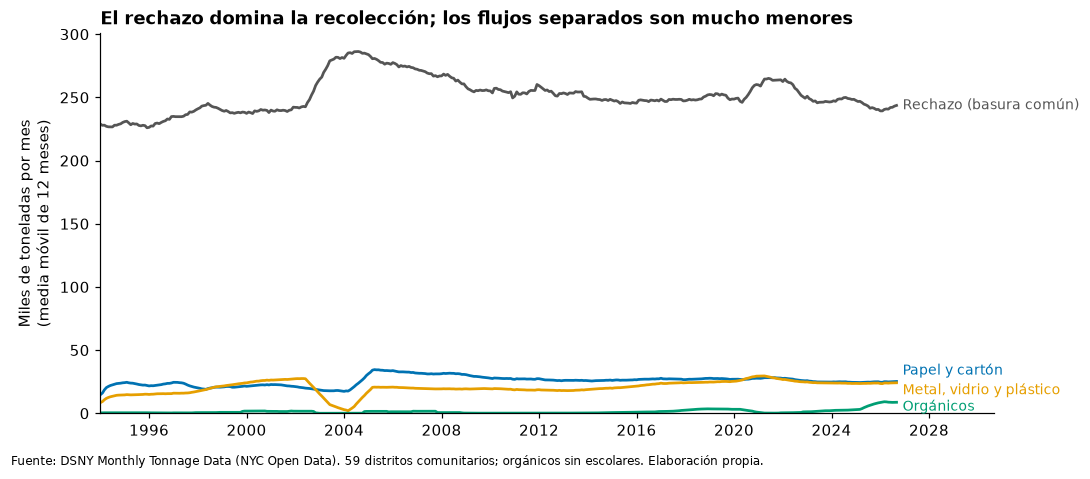

,t_rechazo,t_papel,t_mgp,t_organicos
fecha,,,,
2026-07-01,253.0405,26.0752,26.1250,9.2175
2026-08-01,246.0825,24.2949,24.0957,9.1866
2026-09-01,255.4457,26.7361,24.5425,9.2515


In [13]:
# Figura 2 · Toneladas mensuales de la ciudad por flujo
# Se parte de 1992 porque 1990-1991 tienen meses con menos de 59 distritos
ciudad = df[df.fecha >= "1992-01-01"].groupby("fecha")[["t_rechazo", "t_papel", "t_mgp", "t_organicos"]].sum() / 1000
fig, ax = plt.subplots(figsize=(10, 4.2))
for col, nombre, color, dy in [("t_rechazo", "Rechazo (basura común)", OI["rechazo"], 0),
                               ("t_papel", "Papel y cartón", OI["papel"], 7),
                               ("t_mgp", "Metal, vidrio y plástico", OI["mgp"], -5),
                               ("t_organicos", "Orgánicos", OI["organicos"], -3)]:
    s = ciudad[col].rolling(12, min_periods=12).mean().dropna()
    ax.plot(s.index, s.values, color=color, lw=1.8)
    ax.annotate(nombre, (s.index[-1], s.values[-1]), xytext=(4, dy), textcoords="offset points",
                color=color, va="center", fontsize=9)
ax.set_ylim(0)
ax.set_ylabel("Miles de toneladas por mes\n(media móvil de 12 meses)")
ax.set_title("El rechazo domina la recolección; los flujos separados son mucho menores",
             loc="left", fontweight="bold")
# Papel y MGP empiezan a registrarse en 1993: la media móvil es comparable desde 1994
ax.set_xlim(pd.Timestamp("1994-01-01"), ciudad.index.max() + pd.DateOffset(years=4))
fig.text(0.01, -0.02, "Fuente: DSNY Monthly Tonnage Data (NYC Open Data). 59 distritos comunitarios; "
         "orgánicos sin escolares. Elaboración propia.", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig2_serie_ciudad_por_flujo.png", bbox_inches="tight")
plt.show()
ciudad.tail(3)

In [14]:
# Tasa de desvío anual de la ciudad (años completos desde 2015)
anual = df[df.fecha.dt.year.between(2015, 2025)].groupby(df.fecha.dt.year)[["t_total", "t_desviado"]].sum()
anual["tasa_desvio_pct"] = (anual["t_desviado"] / anual["t_total"] * 100).round(1)
anual.to_csv(TAB / "tasa_desvio_anual_ciudad.csv")
anual

,t_total,t_desviado,tasa_desvio_pct
fecha,,,
2015,3533259.8,586024.0,16.6
2016,3591176.2,625428.1,17.4
2017,3603404.8,636897.5,17.7
2018,3692279.3,668845.2,18.1
2019,3648338.0,663910.5,18.2
2020,3819214.8,697139.5,18.3
2021,3830756.2,663831.4,17.3
2022,3611855.4,619735.6,17.2
2023,3563580.8,607349.2,17.0


In [15]:
# Ventana de referencia para el resto del perfilamiento: últimos 12 meses completos
fin = df["fecha"].max()
ini = fin - pd.DateOffset(months=11)
u12 = df[df["fecha"].between(ini, fin)]
print("Ventana:", ini.strftime("%Y-%m"), "a", fin.strftime("%Y-%m"), "| filas:", len(u12))

dist = (u12.groupby(["boro_cd", "BOROUGH", "nombre_distrito", "poblacion_2010"], dropna=False)
        [["t_rechazo", "t_papel", "t_mgp", "t_organicos", "t_total", "t_desviado"]].sum().reset_index())
dist["tasa_desvio"] = dist["t_desviado"] / dist["t_total"]
dist["kg_hab_dia"] = dist["t_total"] * KG_POR_TON / dist["poblacion_2010"] / 365
dist.to_csv(TAB / "resumen_distritos_ult12m.csv", index=False)
dist[["tasa_desvio", "kg_hab_dia", "t_total"]].describe().round(3)

Ventana: 2025-10 a 2026-09 | filas: 708


,tasa_desvio,kg_hab_dia,t_total
count,59.000,59.000,59.000
mean,0.196,1.149,61359.332
std,0.059,0.524,21368.897
min,0.057,0.710,26105.700
25%,0.155,0.952,45189.700
50%,0.199,1.050,58613.500
75%,0.237,1.230,73998.000
max,0.317,4.717,127505.200


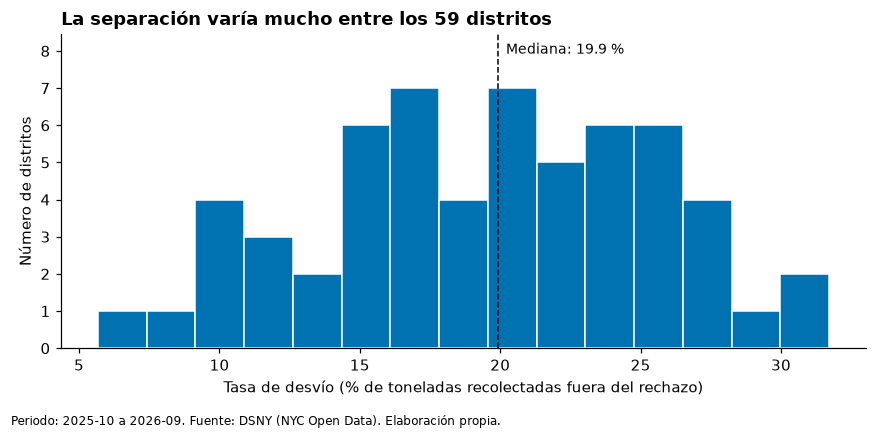

In [16]:
# Figura 3 · Distribución de la tasa de desvío entre distritos (últimos 12 meses)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(dist["tasa_desvio"] * 100, bins=15, color=OI["papel"], edgecolor="white")
med = dist["tasa_desvio"].median() * 100
ax.axvline(med, color="black", lw=1, ls="--")
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.annotate(f"Mediana: {med:.1f} %", (med, ax.get_ylim()[1] * 0.95), xytext=(5, 0),
            textcoords="offset points", fontsize=9, va="center")
ax.set_xlabel("Tasa de desvío (% de toneladas recolectadas fuera del rechazo)")
ax.set_ylabel("Número de distritos")
ax.set_title("La separación varía mucho entre los 59 distritos", loc="left", fontweight="bold")
fig.text(0.01, -0.03, f"Periodo: {ini:%Y-%m} a {fin:%Y-%m}. Fuente: DSNY (NYC Open Data). Elaboración propia.",
         fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig3_distribucion_tasa_desvio.png", bbox_inches="tight")
plt.show()

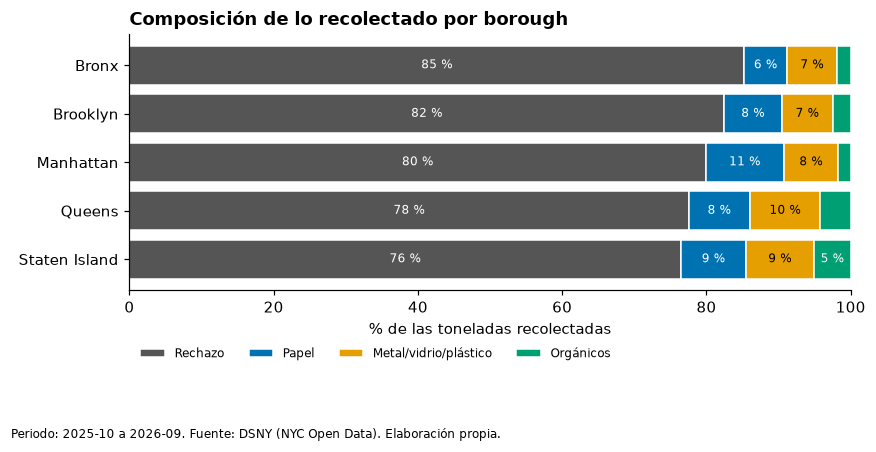

,t_rechazo,t_papel,t_mgp,t_organicos
BOROUGH,,,,
Staten Island,76.4,9.0,9.4,5.1
Queens,77.5,8.5,9.8,4.2
Manhattan,79.9,10.8,7.6,1.7
Brooklyn,82.4,8.0,7.0,2.5
Bronx,85.2,5.9,7.0,1.9


In [17]:
# Figura 4 · Composición por borough (barras 100 %)
comp = u12.groupby("BOROUGH")[["t_rechazo", "t_papel", "t_mgp", "t_organicos"]].sum()
comp = comp.div(comp.sum(axis=1), axis=0).sort_values("t_rechazo") * 100
fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(comp))
for col, nombre in [("t_rechazo", "Rechazo"), ("t_papel", "Papel"), ("t_mgp", "Metal/vidrio/plástico"),
                    ("t_organicos", "Orgánicos")]:
    color = OI[col[2:]]
    ax.barh(comp.index, comp[col], left=left, color=color, label=nombre, edgecolor="white")
    for i, (l, v) in enumerate(zip(left, comp[col])):
        if v >= 5:
            ax.text(l + v / 2, i, f"{v:.0f} %", ha="center", va="center", fontsize=8,
                    color="white" if col != "t_mgp" else "black")
    left += comp[col].values
ax.set_xlim(0, 100)
ax.set_xlabel("% de las toneladas recolectadas")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.18), frameon=False, fontsize=8)
ax.set_title("Composición de lo recolectado por borough", loc="left", fontweight="bold")
fig.text(0.01, -0.12, f"Periodo: {ini:%Y-%m} a {fin:%Y-%m}. Fuente: DSNY (NYC Open Data). Elaboración propia.",
         fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig4_composicion_borough.png", bbox_inches="tight")
plt.show()
comp.round(1)

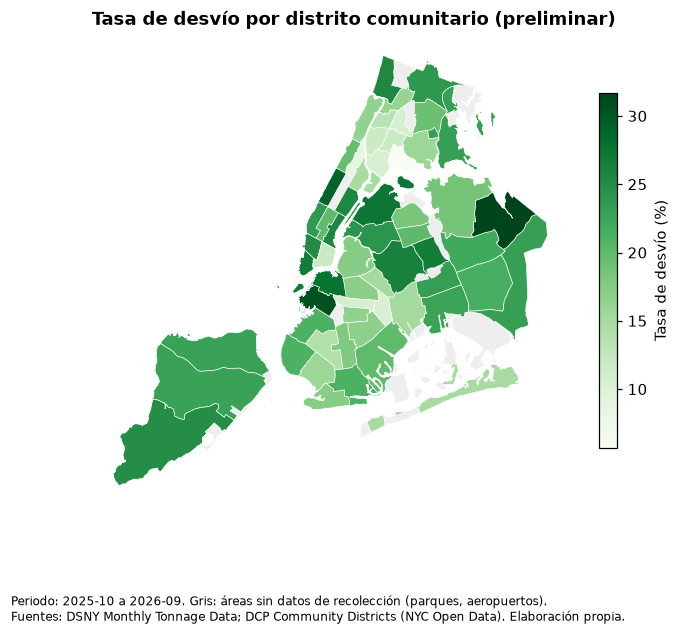

In [18]:
# Figura 5 · Mapa coroplético preliminar de la tasa de desvío
mapa = cd_gdf.merge(dist, on="boro_cd", how="left")
mapa_m = mapa.to_crs(2263)  # NAD83 / New York Long Island (ft): proyección local para dibujar
mapa_m["desvio_pct"] = mapa_m["tasa_desvio"] * 100
fig, ax = plt.subplots(figsize=(7, 7))
mapa_m[mapa_m["tasa_desvio"].isna()].plot(ax=ax, color="#eeeeee", edgecolor="white", lw=0.4)
mapa_m[mapa_m["tasa_desvio"].notna()].plot(
    ax=ax, column="desvio_pct", cmap="Greens", edgecolor="white", lw=0.4, legend=True,
    legend_kwds={"label": "Tasa de desvío (%)", "shrink": 0.6})
ax.set_axis_off()
ax.set_title("Tasa de desvío por distrito comunitario (preliminar)", loc="left", fontweight="bold")
fig.text(0.02, 0.04, f"Periodo: {ini:%Y-%m} a {fin:%Y-%m}. Gris: áreas sin datos de recolección (parques, aeropuertos).\n"
         "Fuentes: DSNY Monthly Tonnage Data; DCP Community Districts (NYC Open Data). Elaboración propia.",
         fontsize=8)
fig.savefig(FIG / "fig5_mapa_tasa_desvio.png", bbox_inches="tight")
plt.show()

In [19]:
# Distritos extremos (para la ficha, sin conclusiones todavía)
cols = ["boro_cd", "BOROUGH", "nombre_distrito", "tasa_desvio", "kg_hab_dia", "t_total"]
extremos = pd.concat([dist.nsmallest(5, "tasa_desvio")[cols].assign(grupo="menor desvío"),
                      dist.nlargest(5, "tasa_desvio")[cols].assign(grupo="mayor desvío")])
extremos.to_csv(TAB / "distritos_extremos.csv", index=False)
extremos.round(3)

,boro_cd,BOROUGH,nombre_distrito,tasa_desvio,kg_hab_dia,t_total,grupo
13,202,Bronx,"Hunts Point, Longwood",0.057,4.717,99159.4,menor desvío
9,110,Manhattan,Central Harlem,0.088,1.685,78444.7,menor desvío
39,316,Brooklyn,"Brownsville, Ocean Hill",0.102,1.122,39049.8,menor desvío
12,201,Bronx,"Melrose, Mott Haven, Port Morris",0.106,1.219,44892.5,menor desvío
17,206,Bronx,"East Tremont, Belmont",0.106,1.325,44383.7,menor desvío
52,411,Queens,"Bayside, Douglaston, Little Neck",0.317,0.971,45486.9,mayor desvío
29,306,Brooklyn,"Park Slope, Carroll Gardens",0.308,0.935,39375.6,mayor desvío
6,107,Manhattan,"West Side, Upper West Side",0.292,0.894,75246.3,mayor desvío
25,302,Brooklyn,"Brooklyn Heights, Fort Greene",0.277,1.219,48844.5,mayor desvío
42,401,Queens,"Astoria, Long Island City",0.273,0.856,65796.6,mayor desvío


## 6. Guardado del archivo procesado (versión 0)

El archivo procesado se guarda **separado** del bruto. Se registran conteos y sumas de control.

In [20]:
salida = df[["fecha", "BOROUGH", "BOROUGH_ID", "COMMUNITYDISTRICT", "boro_cd", "nombre_distrito", "poblacion_2010",
             *TON_COLS, "t_rechazo", "t_papel", "t_mgp", "t_organicos", "t_total", "t_desviado", "tasa_desvio"]]
salida.to_csv(PROC / "dsny_tonelaje_procesado_v0.csv", index=False)
salida.to_parquet(PROC / "dsny_tonelaje_procesado_v0.parquet", index=False)

bitacora = pd.DataFrame([
    {"paso": "lectura bruto", "filas": len(raw), "suma_rechazo_t": round(raw["REFUSETONSCOLLECTED"].sum(), 1)},
    {"paso": "procesado v0", "filas": len(salida), "suma_rechazo_t": round(salida["t_rechazo"].sum(), 1)},
])
bitacora.to_csv(TAB / "bitacora_conteos.csv", index=False)
resumen = {"generado": str(date.today()), "ventana_ult12m": [f"{ini:%Y-%m}", f"{fin:%Y-%m}"],
           "periodo_incompleto": "1990-01 a 1991-12 (meses con menos de 59 distritos)",
           **{k: (v if not isinstance(v, (np.integer,)) else int(v)) for k, v in checks.items()}}
(TAB / "resumen_entrega1.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
bitacora

,paso,filas,suma_rechazo_t
0,lectura bruto,25296,107252492.0
1,procesado v0,25296,107252492.0
